# 04 · Do announcements line up with capex?

The project has two dependent variables that have never been checked against each other:

* **Announcements** (`data/manual/investment_announcements.csv`, 34 events) — what a company *said* it would build. The exploratory models in `final-deliverable/model/` predict these.
* **Capex** (`data/processed/company_capex_annual.csv`, FY23–FY26) — what a company actually *spent* on plant, from filed cash-flow statements. Notebook 03 tested EV volume against this and found a null.

If announcing companies go on to spend more, the two are the same signal seen at two speeds and the two halves of the project tell one story. If they don't, announcements are a different thing from spending, and the models' target should be read as "intent", not "investment".

Indian fiscal years run April–March, so FY26 = April 2025 to March 2026.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

ROOT = Path('..') if Path('../data').exists() else Path('.')
FIG = ROOT / 'notebook-590' / 'figures'
FIG.mkdir(exist_ok=True)

BLUE, ORANGE, GREY, INK2, GRID = '#2a78d6', '#eb6834', '#8a8984', '#52514e', '#e4e3df'
plt.rcParams.update({'font.size': 9, 'axes.edgecolor': GRID, 'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': GRID,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'xtick.color': INK2, 'ytick.color': INK2, 'axes.labelcolor': INK2})

ann = pd.read_csv(ROOT / 'data/manual/investment_announcements.csv')
capex = pd.read_csv(ROOT / 'data/processed/company_capex_annual.csv')
print(len(ann), 'announcements;', len(capex), 'company-years of capex')

34 announcements; 182 company-years of capex


## 1. Match company names

The two files spell names differently (`Exide Industries` vs `Exide Industries Limited`). Lower-casing and dropping "limited" matches all but three. The three that don't match have no FY23–FY26 cash-flow history in the feed: Ather (listed 2025), Zelio (unlisted) and Tata Motors Passenger Vehicles (the post-demerger entity; the capex file's `Tata Motors Limited` is a different company now), so they are left out rather than forced.

In [2]:
def name_key(name):
    return name.lower().replace(' limited', '').strip()

ann['key'] = ann['company'].map(name_key)
capex['key'] = capex['company'].map(name_key)

unmatched = sorted(set(ann['key']) - set(capex['key']))
print('Not in the capex file:', unmatched)

Not in the capex file: ['ather energy', 'tata motors passenger vehicles', 'zelio e-mobility']


## 2. Put both on the same fiscal year

An announcement dated 2026-07-02 falls in FY27. Some announcements are only dated to a fiscal year (`FY2026`); those are used as given. Capex rows are labelled like `Q4 FY24`; the last two digits are the fiscal year.

In [3]:
def to_fiscal_year(date_text):
    if date_text.startswith('FY'):          # 'FY2026' -> 26
        return int(date_text[4:])
    year, month = int(date_text[:4]), int(date_text[5:7])
    if month >= 4:                          # April onwards belongs to the next FY
        year = year + 1
    return year - 2000

ann['fy'] = ann['announcement_date'].map(to_fiscal_year)
capex['fy'] = capex['fiscal_period'].str[-2:].astype(int)

# keep FY23-FY26 and drop zero-capex rows (they break the growth calculation)
capex = capex[(capex['fy'] >= 23) & (capex['capex_cr'] > 0)].sort_values(['key', 'fy'])

print('Announcements by fiscal year:')
print(ann['fy'].value_counts().sort_index())

Announcements by fiscal year:
fy
22     1
23     1
24     3
25     4
26     9
27    16
Name: count, dtype: int64


**The first thing this shows is a timing problem.** 16 of the 34 announcements are dated FY27, a year with no filed capex yet. Only the 17 announcements in FY23–FY26 can be checked against spending at all.

## 3. The two series side by side

Total capex for the primary-panel companies (within a few percent of the totals the root README quotes) against the number of announcements per fiscal year.

      panel_capex_cr  announcements
FY23         30310.0              1
FY24         43040.0              3
FY25         53228.0              4
FY26         53137.0              9
FY27             NaN             16


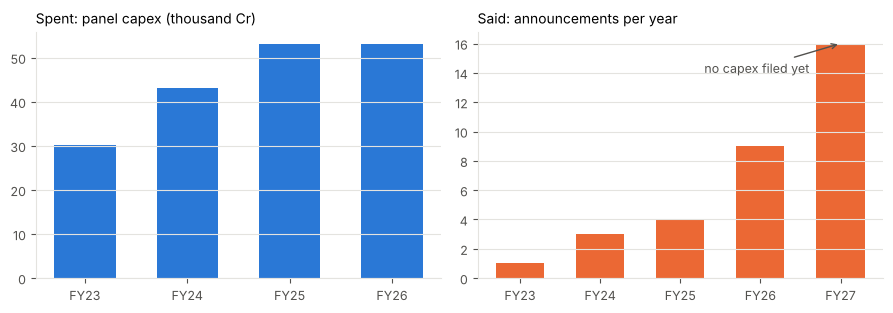

In [4]:
panel = capex[capex['primary_panel'] == 'yes']
by_year = pd.DataFrame({
    'panel_capex_cr': panel.groupby('fy')['capex_cr'].sum(),
    'announcements': ann.groupby('fy').size(),
}).reindex(range(23, 28)).fillna({'announcements': 0})
by_year.index = ['FY' + str(y) for y in by_year.index]
print(by_year.round(0))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.2))
a1.bar(by_year.index[:4], by_year['panel_capex_cr'][:4] / 1000, color=BLUE, width=0.6)
a1.set_title('Spent: panel capex (thousand Cr)', loc='left', fontsize=10)
a2.bar(by_year.index, by_year['announcements'], color=ORANGE, width=0.6)
a2.set_title('Said: announcements per year', loc='left', fontsize=10)
a2.annotate('no capex filed yet', xy=(4, by_year['announcements'].iloc[4]), xytext=(2.3, 14),
            color=INK2, arrowprops=dict(arrowstyle='->', color=INK2))
fig.tight_layout()
fig.savefig(FIG / '04_said_vs_spent_by_year.png', dpi=160)
plt.show()

Spending rose FY23→FY25 and **flattened in FY26**. Announcements were sparse through FY25 and **surged in FY26–FY27**, after the spending ramp. At the sector level, announcements do not lead capex in this window; if anything they come after it.

## 4. Company level: does capex grow faster in a year the company announces?

Capex growth is the log change from the year before (0.20 ≈ +22%). Each company-year is marked by whether that company made an announcement in that fiscal year. Two tests: Welch's t-test (compares means) and Mann–Whitney (compares ranks, safer with a few large outliers).

In [5]:
capex['growth'] = np.log(capex['capex_cr'] / capex.groupby('key')['capex_cr'].shift(1))

events = ann.groupby(['key', 'fy']).size().rename('n_ann').reset_index()
prev_year_events = events.assign(fy=events['fy'] + 1).rename(columns={'n_ann': 'n_ann_prev'})

df = capex.merge(events, on=['key', 'fy'], how='left')
df = df.merge(prev_year_events, on=['key', 'fy'], how='left')
df['announced_this_year'] = df['n_ann'].notna()
df['announced_last_year'] = df['n_ann_prev'].notna()
df = df.dropna(subset=['growth'])          # FY23 has no previous year

def compare(column):
    yes = df[df[column]]['growth']
    no = df[~df[column]]['growth']
    return {'n with': len(yes), 'median growth with': round(yes.median(), 3),
            'n without': len(no), 'median growth without': round(no.median(), 3),
            't-test p': round(stats.ttest_ind(yes, no, equal_var=False).pvalue, 3),
            'Mann-Whitney p': round(stats.mannwhitneyu(yes, no).pvalue, 3)}

results = pd.DataFrame({'same year': compare('announced_this_year'),
                        'year after (lead)': compare('announced_last_year')}).T
results

,n with,median growth with,n without,median growth without,t-test p,Mann-Whitney p
same year,12.0,0.077,121.0,0.205,0.169,0.250
year after (lead),6.0,0.094,127.0,0.199,0.318,0.454


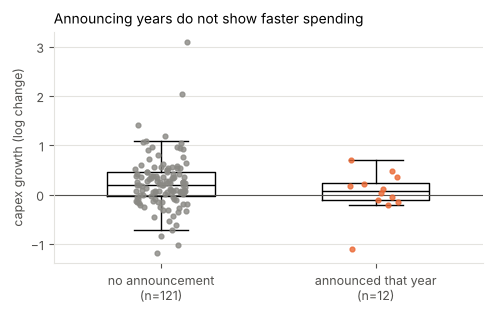

In [6]:
fig, ax = plt.subplots(figsize=(5, 3.2))
groups = [df[~df['announced_this_year']]['growth'], df[df['announced_this_year']]['growth']]
ax.boxplot(groups, widths=0.5, showfliers=False, medianprops=dict(color='black'))
for i, g in enumerate(groups, start=1):
    jitter = np.random.default_rng(0).uniform(-0.12, 0.12, len(g))
    ax.scatter(i + jitter, g, s=12, color=[GREY, ORANGE][i - 1], alpha=0.8, zorder=3)
ax.set_xticks([1, 2], ['no announcement\n(n=%d)' % len(groups[0]), 'announced that year\n(n=%d)' % len(groups[1])])
ax.axhline(0, color=INK2, lw=0.8)
ax.set_ylabel('capex growth (log change)')
ax.set_title('Announcing years do not show faster spending', loc='left', fontsize=10)
fig.tight_layout()
fig.savefig(FIG / '04_capex_growth_by_announcement.png', dpi=160)
plt.show()

## 5. Same companies only

Comparing across companies mixes in who they are (Maruti vs Sona BLW). This step compares each announcing company with **itself**: its growth in the announcement year minus its own average growth. A Wilcoxon signed-rank test asks whether those differences are centred on zero.

In [7]:
announcers = df[df['announced_this_year']]['key'].unique()
own = df[df['key'].isin(announcers)].copy()
own['vs_own_average'] = own['growth'] - own.groupby('key')['growth'].transform('mean')
in_ann_year = own[own['announced_this_year']]['vs_own_average']

print('company-years:', len(in_ann_year))
print('median growth vs own average:', round(in_ann_year.median(), 3))
print('Wilcoxon p:', round(stats.wilcoxon(in_ann_year).pvalue, 3))

company-years: 12
median growth vs own average: -0.166
Wilcoxon p: 0.11


## 6. How big are the announcements against what the company normally spends?

For the announcements that state an amount, divide it by the company's average annual capex over FY23–FY26. A ratio above 1 means the announcement is bigger than a normal year's spending — a multi-year commitment that annual capex will only show later.

In [8]:
stated = ann.dropna(subset=['capex_inr_cr']).copy()
stated = stated[~stated['key'].isin(unmatched)]
avg_capex = capex.groupby('key')['capex_cr'].mean()
stated['avg_annual_capex_cr'] = stated['key'].map(avg_capex).round(0)
stated['times_normal_year'] = (stated['capex_inr_cr'] / stated['avg_annual_capex_cr']).round(2)
stated[['company', 'announcement_date', 'fy', 'capex_inr_cr', 'avg_annual_capex_cr', 'times_normal_year']]

,company,announcement_date,fy,capex_inr_cr,avg_annual_capex_cr,times_normal_year
1,TVS Motor Company,2023-01-11,23,1000.0,2050.0,0.49
2,Sona BLW Precision Forgings,2023-07-27,24,99.7,391.0,0.25
4,Hindalco Industries,2023-12-12,24,800.0,19052.0,0.04
7,Mahindra & Mahindra,2025-01-08,25,4500.0,9062.0,0.50
9,Eicher Motors,2026-02,26,958.0,847.0,1.13
11,Exicom Tele Systems,2026-03-16,26,216.0,137.0,1.58
13,Hero MotoCorp,2026-05,27,1500.0,837.0,1.79
15,Maruti Suzuki India,2026-07-02,27,35000.0,8851.0,3.95
16,Amara Raja Energy & Mobility,2026-07-15,27,500.0,981.0,0.51
17,Maruti Suzuki India,2026-07-30,27,25289.0,8851.0,2.86


In [9]:
early = stated[stated['fy'] <= 25]['times_normal_year']
late = stated[stated['fy'] >= 26]['times_normal_year']
print('FY23-FY25 announcements: median %.2fx a normal year (n=%d)' % (early.median(), len(early)))
print('FY26-FY27 announcements: median %.2fx a normal year (n=%d)' % (late.median(), len(late)))

FY23-FY25 announcements: median 0.37x a normal year (n=4)
FY26-FY27 announcements: median 1.45x a normal year (n=9)


## What this says

1. **Announcements and capex are not the same signal in FY23–FY26.** Company-years with an announcement grew capex *no faster* than the rest — the point estimate is slower — in the same year, the year after, and against the company's own average. None of the differences is significant, and the samples are small (12, 6 and 12 announcing company-years), so the safe reading is "no evidence they move together", not "they move apart".
2. **The timing is the more useful finding.** Sector capex ramped FY23→FY25 and flattened in FY26; announcements surged in FY26–FY27, and the late ones are large — typically more than a normal year's capex (section 6). They look like the start of a *next* round of commitments, not a record of the spending already seen.
3. **For the storyline:** notebook 03 shows the FY23–FY26 capex cycle was sector-wide, not EV-driven. This notebook shows the announcement series the models predict mostly sits *after* that cycle. So the two dependent variables describe different things: capex = the cycle that already happened; announcements = intent for what comes next. That is why the models are framed as predicting announcements, and why their best signal (segment mix) should be judged against the FY27 capex filings when they arrive.

**Limits.** 17 announcements fall in a year with capex data; names were matched by hand-normalised strings; fiscal-year-dated announcements carry no month, so "same year" is the finest timing possible. Re-run this notebook when FY27 filings land (from mid-2027): that is the real test of whether the FY26–FY27 announcements turn into spending.